# 01 - Industrial Dataset Exploration (MVTec AD)
**Team Lead: Tanya (Computer Vision & Anomaly Detection)**

### Objectives:
1. Explore normal industrial images (`train/good`) and defective test samples across **bottle**, **cable**, and **hazelnut**.
2. Compile structured metadata (paths, labels, splits, masks).
3. Visualize defects side-by-side with ground-truth binary masks.

---

In [1]:
# CELL 1: Environment Setup & Automatic Module Deployment
import os
import sys
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print("🚀 Detected Google Colab environment.")
    PROJECT_ROOT = Path('/content')
else:
    print("💻 Detected Local VS Code environment.")
    PROJECT_ROOT = Path('.').resolve()
    if PROJECT_ROOT.name == 'notebooks':
        PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Auto-deploy src/ modules if running in Colab without repo upload
src_target = PROJECT_ROOT / 'src'
if not (src_target / 'preprocessing.py').exists():
    print("📦 Deploying project modules into environment...")
    src_target.mkdir(parents=True, exist_ok=True)
    MODULES = {'__init__.py': '"""\nIndustrial Visual Anomaly Discovery for Quality Inspection\nPackage Initialization\n"""\n\n__version__ = "0.1.0"\n', 'preprocessing.py': '"""\nPreprocessing Module\nHandles dataset parsing, metadata compilation, and standard image transformations\nfor MVTec AD industrial categories (bottle, cable, hazelnut, etc.).\n"""\n\nimport os\nfrom pathlib import Path\nfrom typing import Dict, List, Optional, Tuple, Union\n\nimport numpy as np\nimport pandas as pd\nfrom PIL import Image\n\ntry:\n    import torch\n    from torch.utils.data import Dataset\n    import torchvision.transforms as T\n    TORCH_AVAILABLE = True\nexcept ImportError:\n    TORCH_AVAILABLE = False\n    Dataset = object  # Fallback base class\n\n\n# Standard ImageNet normalization parameters\nIMAGENET_MEAN = [0.485, 0.456, 0.406]\nIMAGENET_STD = [0.229, 0.224, 0.225]\n\n\ndef get_default_transforms(img_size: int = 224, crop_size: int = 224):\n    """\n    Returns standard torchvision preprocessing transforms.\n    Resize -> CenterCrop -> ToTensor -> Normalize (ImageNet stats).\n    """\n    if not TORCH_AVAILABLE:\n        raise ImportError("PyTorch and Torchvision are required for torchvision transforms.")\n\n    return T.Compose([\n        T.Resize((img_size, img_size)),\n        T.CenterCrop(crop_size),\n        T.ToTensor(),\n        T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)\n    ])\n\n\ndef build_mvtec_metadata(\n    dataset_root: Union[str, Path],\n    categories: Optional[List[str]] = None\n) -> pd.DataFrame:\n    """\n    Scans the MVTec AD directory and constructs a structured metadata DataFrame.\n\n    Columns produced:\n    - image_id: unique string identifier\n    - category: e.g. bottle, cable, hazelnut\n    - split: \'train\' or \'test\'\n    - defect_type: e.g. \'good\', \'broken_large\', \'bent_wire\'\n    - is_anomaly: 0 for good (normal), 1 for defective\n    - image_path: absolute or relative path to raw image\n    - mask_path: path to ground-truth binary mask (if defective test sample), else None\n    """\n    root = Path(dataset_root)\n    if not root.exists():\n        raise FileNotFoundError(f"Dataset root \'{dataset_root}\' does not exist.")\n\n    if categories is None:\n        categories = [d.name for d in root.iterdir() if d.is_dir() and not d.name.startswith(\'.\')]\n\n    records = []\n\n    for cat in sorted(categories):\n        cat_dir = root / cat\n        if not cat_dir.is_dir():\n            continue\n\n        # 1. Process \'train\' split (normally only \'good\' subfolder)\n        train_dir = cat_dir / "train"\n        if train_dir.is_dir():\n            for defect_dir in sorted(train_dir.iterdir()):\n                if not defect_dir.is_dir():\n                    continue\n                defect_name = defect_dir.name\n                for img_file in sorted(defect_dir.glob("*.png")):\n                    records.append({\n                        "image_id": f"{cat}_train_{defect_name}_{img_file.stem}",\n                        "category": cat,\n                        "split": "train",\n                        "defect_type": defect_name,\n                        "is_anomaly": 0 if defect_name == "good" else 1,\n                        "image_path": str(img_file.resolve()),\n                        "mask_path": None\n                    })\n\n        # 2. Process \'test\' split (both \'good\' and defect folders)\n        test_dir = cat_dir / "test"\n        gt_dir = cat_dir / "ground_truth"\n\n        if test_dir.is_dir():\n            for defect_dir in sorted(test_dir.iterdir()):\n                if not defect_dir.is_dir():\n                    continue\n                defect_name = defect_dir.name\n                is_anomaly = 0 if defect_name == "good" else 1\n\n                for img_file in sorted(defect_dir.glob("*.png")):\n                    mask_path = None\n                    if is_anomaly and gt_dir.is_dir():\n                        expected_mask = gt_dir / defect_name / f"{img_file.stem}_mask.png"\n                        if expected_mask.exists():\n                            mask_path = str(expected_mask.resolve())\n\n                    records.append({\n                        "image_id": f"{cat}_test_{defect_name}_{img_file.stem}",\n                        "category": cat,\n                        "split": "test",\n                        "defect_type": defect_name,\n                        "is_anomaly": is_anomaly,\n                        "image_path": str(img_file.resolve()),\n                        "mask_path": mask_path\n                    })\n\n    df = pd.DataFrame(\n        records,\n        columns=["image_id", "category", "split", "defect_type", "is_anomaly", "image_path", "mask_path"]\n    )\n    return df\n\n\nclass MVTecDataset(Dataset):\n    """\n    PyTorch Dataset implementation for MVTec Anomaly Detection.\n    """\n    def __init__(\n        self,\n        metadata_df: pd.DataFrame,\n        transform=None,\n        mask_transform=None,\n        target_split: Optional[str] = None,\n        target_category: Optional[str] = None\n    ):\n        df = metadata_df.copy()\n        if target_split is not None:\n            df = df[df["split"] == target_split]\n        if target_category is not None:\n            df = df[df["category"] == target_category]\n\n        self.df = df.reset_index(drop=True)\n        self.transform = transform\n        self.mask_transform = mask_transform\n\n    def __len__(self) -> int:\n        return len(self.df)\n\n    def __getitem__(self, idx: int) -> Dict:\n        row = self.df.iloc[idx]\n        image_path = row["image_path"]\n        mask_path = row["mask_path"]\n\n        # Load RGB image\n        img = Image.open(image_path).convert("RGB")\n        orig_size = img.size  # (W, H)\n\n        if self.transform is not None:\n            img_tensor = self.transform(img)\n        else:\n            img_tensor = np.array(img)\n\n        # Load ground truth mask if available\n        mask_tensor = None\n        if mask_path is not None and os.path.exists(mask_path):\n            mask = Image.open(mask_path).convert("L")\n            if self.mask_transform is not None:\n                mask_tensor = self.mask_transform(mask)\n            elif TORCH_AVAILABLE:\n                # Default binarization: Resize and convert to tensor (0.0 or 1.0)\n                mask_tensor = T.functional.to_tensor(mask.resize((224, 224), Image.NEAREST))\n                mask_tensor = (mask_tensor > 0.5).float()\n            else:\n                mask_tensor = np.array(mask) > 128\n        else:\n            if TORCH_AVAILABLE:\n                mask_tensor = torch.zeros((1, 224, 224), dtype=torch.float32)\n            else:\n                mask_tensor = np.zeros((224, 224), dtype=np.float32)\n\n        return {\n            "image": img_tensor,\n            "mask": mask_tensor,\n            "is_anomaly": int(row["is_anomaly"]),\n            "category": row["category"],\n            "defect_type": row["defect_type"],\n            "split": row["split"],\n            "image_id": row["image_id"],\n            "image_path": image_path,\n            "orig_size": orig_size\n        }\n\n\nif __name__ == "__main__":\n    # Test metadata builder\n    sample_root = Path("data/mvtec")\n    if sample_root.exists():\n        df = build_mvtec_metadata(sample_root, categories=["bottle", "cable", "hazelnut"])\n        print(f"Metadata created with {len(df)} total samples.")\n        print(df.groupby(["category", "split", "is_anomaly"]).size())\n', 'feature_extraction.py': '"""\nFeature Extraction Module\nExtracts deep representations from industrial images using pretrained CNNs (ResNet / EfficientNet).\nSupports:\n1. Global image-level embeddings (for PCA, t-SNE, Clustering - Gayathri\'s pipeline)\n2. Patch-level spatial feature maps (for PatchCore / Memory Bank - Tanya\'s pipeline)\n"""\n\nimport os\nfrom pathlib import Path\nfrom typing import Dict, List, Optional, Tuple, Union\n\nimport numpy as np\nimport pandas as pd\nfrom PIL import Image\n\ntry:\n    import torch\n    import torch.nn as nn\n    import torch.nn.functional as F\n    import torchvision.models as models\n    from torchvision.models import ResNet50_Weights, ResNet18_Weights\n    TORCH_AVAILABLE = True\nexcept ImportError:\n    TORCH_AVAILABLE = False\n\n\nclass DeepFeatureExtractor:\n    """\n    Extracts deep embeddings from intermediate and final layers of a CNN backbone.\n    """\n    def __init__(\n        self,\n        backbone_name: str = "resnet50",\n        pretrained: bool = True,\n        device: Optional[str] = None\n    ):\n        if not TORCH_AVAILABLE:\n            raise ImportError(\n                "PyTorch and Torchvision are required for DeepFeatureExtractor. "\n                "Please run on Google Colab or install torch locally."\n            )\n\n        if device is None:\n            self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")\n        else:\n            self.device = torch.device(device)\n\n        self.backbone_name = backbone_name.lower()\n        self._init_backbone(pretrained)\n\n    def _init_backbone(self, pretrained: bool):\n        if self.backbone_name == "resnet50":\n            weights = ResNet50_Weights.DEFAULT if pretrained else None\n            backbone = models.resnet50(weights=weights)\n        elif self.backbone_name == "resnet18":\n            weights = ResNet18_Weights.DEFAULT if pretrained else None\n            backbone = models.resnet18(weights=weights)\n        else:\n            raise ValueError(f"Unsupported backbone: {self.backbone_name}")\n\n        backbone.eval()\n        for param in backbone.parameters():\n            param.requires_grad = False\n\n        self.backbone = backbone.to(self.device)\n\n        # Hook storage for intermediate patch feature maps\n        self.features: Dict[str, torch.Tensor] = {}\n        self._register_hooks()\n\n    def _register_hooks(self):\n        def hook_fn(name):\n            def _hook(module, input, output):\n                self.features[name] = output\n            return _hook\n\n        # Register forward hooks on intermediate layers for patch extraction\n        if hasattr(self.backbone, "layer2"):\n            self.backbone.layer2.register_forward_hook(hook_fn("layer2"))\n        if hasattr(self.backbone, "layer3"):\n            self.backbone.layer3.register_forward_hook(hook_fn("layer3"))\n\n    def extract_image_embedding(self, x: "torch.Tensor") -> np.ndarray:\n        """\n        Extracts global pooled image embedding vector (e.g. 2048-dim for ResNet50).\n        """\n        if x.dim() == 3:\n            x = x.unsqueeze(0)\n        x = x.to(self.device)\n\n        with torch.no_grad():\n            # Pass through stem and conv layers\n            out = self.backbone.conv1(x)\n            out = self.backbone.bn1(out)\n            out = self.backbone.relu(out)\n            out = self.backbone.maxpool(out)\n\n            out = self.backbone.layer1(out)\n            out = self.backbone.layer2(out)\n            out = self.backbone.layer3(out)\n            out = self.backbone.layer4(out)\n\n            # Global average pooling\n            pooled = self.backbone.avgpool(out)\n            embedding = torch.flatten(pooled, 1)\n\n        return embedding.cpu().numpy()\n\n    def extract_patch_features(\n        self,\n        x: "torch.Tensor",\n        target_size: Tuple[int, int] = (28, 28)\n    ) -> "torch.Tensor":\n        """\n        Extracts multi-scale patch features from layer2 & layer3, resized to target_size.\n        Used for PatchCore memory bank and pixel-level anomaly localization.\n        Returns: Tensor of shape (B, channels, target_size[0], target_size[1])\n        """\n        if x.dim() == 3:\n            x = x.unsqueeze(0)\n        x = x.to(self.device)\n        self.features.clear()\n\n        with torch.no_grad():\n            _ = self.backbone(x)\n            f_l2 = self.features["layer2"]\n            f_l3 = self.features["layer3"]\n\n            # Align spatial dimensions using bilinear interpolation\n            f_l2_resized = F.interpolate(f_l2, size=target_size, mode="bilinear", align_corners=False)\n            f_l3_resized = F.interpolate(f_l3, size=target_size, mode="bilinear", align_corners=False)\n\n            # Concatenate multi-scale representations\n            patch_features = torch.cat([f_l2_resized, f_l3_resized], dim=1)\n\n        return patch_features\n\n\ndef extract_and_save_dataset_features(\n    metadata_df: pd.DataFrame,\n    output_dir: Union[str, Path] = "data/embeddings",\n    backbone_name: str = "resnet50",\n    batch_size: int = 16,\n    device: Optional[str] = None\n) -> Tuple[np.ndarray, pd.DataFrame]:\n    """\n    Extracts global image embeddings for all samples in metadata_df and persists them.\n    Deliverable for Gayathri\'s PCA, t-SNE, and Clustering pipeline.\n    """\n    from src.preprocessing import MVTecDataset, get_default_transforms\n\n    out_path = Path(output_dir)\n    out_path.mkdir(parents=True, exist_ok=True)\n\n    extractor = DeepFeatureExtractor(backbone_name=backbone_name, device=device)\n    transforms = get_default_transforms(img_size=224, crop_size=224)\n\n    dataset = MVTecDataset(metadata_df=metadata_df, transform=transforms)\n    dataloader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=0)\n\n    all_embeddings = []\n    print(f"Extracting features for {len(dataset)} samples using {backbone_name} on {extractor.device}...")\n\n    for batch_idx, batch in enumerate(dataloader):\n        imgs = batch["image"]\n        embeddings = extractor.extract_image_embedding(imgs)\n        all_embeddings.append(embeddings)\n\n        if (batch_idx + 1) % 10 == 0 or (batch_idx + 1) == len(dataloader):\n            print(f"Processed batch {batch_idx + 1}/{len(dataloader)}")\n\n    embeddings_matrix = np.vstack(all_embeddings)\n\n    # Save array and accompanying metadata\n    npy_path = out_path / "image_embeddings.npy"\n    csv_path = out_path / "metadata.csv"\n\n    np.save(npy_path, embeddings_matrix)\n    metadata_df.to_csv(csv_path, index=False)\n\n    print(f"Saved embeddings matrix of shape {embeddings_matrix.shape} to {npy_path}")\n    print(f"Saved metadata index to {csv_path}")\n\n    return embeddings_matrix, metadata_df\n', 'anomaly_detection.py': '"""\nAnomaly Detection Module\nImplements Memory Bank & Nearest-Neighbour / PatchCore-style Anomaly Detection.\nStrictly fits on normal training images (train/good) and evaluates on test images.\n"""\n\nfrom pathlib import Path\nfrom typing import Dict, List, Optional, Tuple, Union\n\nimport numpy as np\nfrom scipy.ndimage import gaussian_filter\nfrom sklearn.neighbors import NearestNeighbors\n\ntry:\n    import torch\n    import torch.nn.functional as F\n    TORCH_AVAILABLE = True\nexcept ImportError:\n    TORCH_AVAILABLE = False\n\n\nclass MemoryBankAnomalyDetector:\n    """\n    PatchCore-style memory bank anomaly detector.\n\n    Key principles:\n    1. Memory bank is populated ONLY with patch features from pristine \'train/good\' images.\n    2. Test image anomaly score is calculated using nearest-neighbour distance to the memory bank.\n    3. Patch anomaly scores are reshaped to spatial grid and upsampled to form an anomaly heatmap.\n    """\n    def __init__(\n        self,\n        n_neighbors: int = 1,\n        subsample_ratio: float = 0.1,\n        gaussian_sigma: float = 4.0,\n        random_state: int = 42\n    ):\n        self.n_neighbors = n_neighbors\n        self.subsample_ratio = subsample_ratio\n        self.gaussian_sigma = gaussian_sigma\n        self.random_state = random_state\n\n        self.memory_bank: Optional[np.ndarray] = None\n        self.nn_index: Optional[NearestNeighbors] = None\n\n    def fit(self, normal_patch_features: np.ndarray):\n        """\n        Builds the memory bank from normal training patches.\n        Args:\n            normal_patch_features: shape (N_patches, Feature_dim)\n        """\n        rng = np.random.RandomState(self.random_state)\n        total_patches = normal_patch_features.shape[0]\n\n        # Coreset subsampling (or random subsampling for efficiency)\n        if self.subsample_ratio < 1.0:\n            sample_size = max(1, int(total_patches * self.subsample_ratio))\n            indices = rng.choice(total_patches, size=sample_size, replace=False)\n            self.memory_bank = normal_patch_features[indices]\n        else:\n            self.memory_bank = normal_patch_features\n\n        # Fit Scikit-Learn NearestNeighbors index\n        self.nn_index = NearestNeighbors(\n            n_neighbors=self.n_neighbors,\n            algorithm="auto",\n            metric="euclidean"\n        )\n        self.nn_index.fit(self.memory_bank)\n        print(f"Memory bank built with {self.memory_bank.shape[0]} normal patch vectors (dim={self.memory_bank.shape[1]}).")\n\n    def predict_image_and_map(\n        self,\n        patch_features: np.ndarray,\n        spatial_grid: Tuple[int, int] = (28, 28),\n        target_size: Tuple[int, int] = (224, 224)\n    ) -> Tuple[float, np.ndarray]:\n        """\n        Calculates anomaly score and 2D anomaly heatmap for a single test image.\n        Args:\n            patch_features: shape (H*W, feature_dim)\n            spatial_grid: (H_feat, W_feat), e.g. (28, 28)\n            target_size: original image dimensions (H, W), e.g. (224, 224)\n        Returns:\n            image_score: float (maximum patch distance)\n            anomaly_map: shape target_size (smoothed heatmap)\n        """\n        if self.nn_index is None:\n            raise RuntimeError("MemoryBankAnomalyDetector is not fitted yet. Call fit() first.")\n\n        # Compute nearest-neighbour distance to normal memory bank\n        distances, _ = self.nn_index.kneighbors(patch_features)\n        patch_scores = distances[:, 0]  # distance to nearest normal neighbor\n\n        # Maximum patch distance is the image-level anomaly score\n        image_score = float(np.max(patch_scores))\n\n        # Reshape to 2D feature map\n        h_grid, w_grid = spatial_grid\n        feat_map = patch_scores.reshape((h_grid, w_grid))\n\n        # Resize feature map to target image dimensions using PIL or SciPy\n        from PIL import Image\n        feat_img = Image.fromarray(feat_map)\n        resized_map = feat_img.resize((target_size[1], target_size[0]), resample=Image.BILINEAR)\n        anomaly_map = np.array(resized_map, dtype=np.float32)\n\n        # Smooth using Gaussian filter\n        if self.gaussian_sigma > 0:\n            anomaly_map = gaussian_filter(anomaly_map, sigma=self.gaussian_sigma)\n\n        return image_score, anomaly_map\n\n    def predict_batch_scores(self, image_patch_list: List[np.ndarray]) -> np.ndarray:\n        """\n        Computes image-level anomaly scores for a list of test images.\n        """\n        scores = []\n        for patches in image_patch_list:\n            score, _ = self.predict_image_and_map(patches)\n            scores.append(score)\n        return np.array(scores)\n', 'visualization.py': '"""\nVisualization Module\nGenerates anomaly heatmaps, overlay blends, side-by-side defect comparisons,\nand ROC / PR evaluation curves.\n"""\n\nfrom pathlib import Path\nfrom typing import Optional, Tuple, Union\n\nimport matplotlib.pyplot as plt\nimport numpy as np\nfrom PIL import Image\n\n\ndef normalize_map(heatmap: np.ndarray) -> np.ndarray:\n    """Normalizes array to range [0, 1]."""\n    min_val = np.min(heatmap)\n    max_val = np.max(heatmap)\n    if max_val - min_val > 1e-8:\n        return (heatmap - min_val) / (max_val - min_val)\n    return np.zeros_like(heatmap)\n\n\ndef overlay_heatmap_on_image(\n    image: Union[np.ndarray, Image.Image],\n    heatmap: np.ndarray,\n    alpha: float = 0.5,\n    cmap: str = "jet"\n) -> np.ndarray:\n    """\n    Overlays a continuous anomaly heatmap onto an RGB image.\n    Args:\n        image: RGB numpy array (H, W, 3) in [0, 255] or PIL Image\n        heatmap: 2D numpy array (H, W)\n        alpha: image blending weight (1-alpha is heatmap weight)\n        cmap: matplotlib colormap name (\'jet\', \'plasma\', \'inferno\')\n    Returns:\n        blended: RGB uint8 numpy array (H, W, 3)\n    """\n    if isinstance(image, Image.Image):\n        image = np.array(image)\n\n    # Normalize heatmap\n    norm_map = normalize_map(heatmap)\n\n    # Apply colormap\n    colormap = plt.get_cmap(cmap)\n    colored_map = colormap(norm_map)[:, :, :3]  # (H, W, 3) in [0, 1]\n    colored_map = (colored_map * 255).astype(np.uint8)\n\n    # Resize image if dimensions mismatch\n    if image.shape[:2] != heatmap.shape[:2]:\n        img_pil = Image.fromarray(image).resize((heatmap.shape[1], heatmap.shape[0]))\n        image = np.array(img_pil)\n\n    # Alpha blend\n    blended = (alpha * image + (1.0 - alpha) * colored_map).astype(np.uint8)\n    return blended\n\n\ndef plot_anomaly_comparison(\n    image: Union[np.ndarray, Image.Image],\n    ground_truth_mask: Optional[np.ndarray],\n    anomaly_map: np.ndarray,\n    anomaly_score: float,\n    defect_type: str = "defect",\n    category: str = "bottle",\n    save_path: Optional[Union[str, Path]] = None\n):\n    """\n    Plots a multi-panel visual inspection:\n    [Input Image | Ground Truth Mask | Predicted Anomaly Map | Anomaly Overlay]\n    """\n    if isinstance(image, Image.Image):\n        image = np.array(image)\n\n    overlay = overlay_heatmap_on_image(image, anomaly_map)\n\n    fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))\n\n    # 1. Original Image\n    axes[0].imshow(image)\n    axes[0].set_title(f"Input: {category} ({defect_type})", fontsize=11, fontweight="bold")\n    axes[0].axis("off")\n\n    # 2. Ground Truth Mask\n    if ground_truth_mask is not None and np.sum(ground_truth_mask) > 0:\n        axes[1].imshow(ground_truth_mask, cmap="gray")\n        axes[1].set_title("Ground Truth Mask", fontsize=11, fontweight="bold")\n    else:\n        axes[1].imshow(np.zeros_like(anomaly_map), cmap="gray")\n        axes[1].set_title("Ground Truth: Normal (No Defect)", fontsize=11)\n    axes[1].axis("off")\n\n    # 3. Anomaly Map\n    im = axes[2].imshow(anomaly_map, cmap="jet")\n    axes[2].set_title(f"Anomaly Map (Score: {anomaly_score:.3f})", fontsize=11, fontweight="bold")\n    axes[2].axis("off")\n    fig.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)\n\n    # 4. Anomaly Overlay\n    axes[3].imshow(overlay)\n    axes[3].set_title("Inspection Overlay", fontsize=11, fontweight="bold")\n    axes[3].axis("off")\n\n    plt.tight_layout()\n\n    if save_path:\n        Path(save_path).parent.mkdir(parents=True, exist_ok=True)\n        plt.savefig(save_path, dpi=200, bbox_inches="tight")\n        print(f"Saved comparison plot to {save_path}")\n\n    return fig\n', 'evaluation.py': '"""\nEvaluation Module\nComputes performance metrics for visual anomaly detection:\n- Image-level AUROC and AUPRC (Average Precision)\n- Pixel-level AUROC (Localization accuracy against ground truth masks)\n- Optimal decision thresholds, Confusion Matrix, Precision, Recall, and F1-score\n"""\n\nfrom pathlib import Path\nfrom typing import Dict, List, Optional, Tuple, Union\n\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\nfrom sklearn.metrics import (\n    auc,\n    confusion_matrix,\n    f1_score,\n    precision_recall_curve,\n    precision_score,\n    recall_score,\n    roc_auc_score,\n    roc_curve,\n)\n\n\ndef evaluate_image_level(\n    y_true: np.ndarray,\n    y_scores: np.ndarray,\n    category_name: str = "all"\n) -> Dict[str, float]:\n    """\n    Computes image-level AUROC, AUPRC, and optimal threshold metrics.\n    """\n    y_true = np.asarray(y_true, dtype=int)\n    y_scores = np.asarray(y_scores, dtype=float)\n\n    # 1. ROC and AUROC\n    fpr, tpr, roc_thresholds = roc_curve(y_true, y_scores)\n    auroc = roc_auc_score(y_true, y_scores)\n\n    # 2. Precision-Recall and AUPRC\n    precisions, recalls, pr_thresholds = precision_recall_curve(y_true, y_scores)\n    auprc = auc(recalls, precisions)\n\n    # 3. Find optimal threshold using Youden\'s J statistic (TPR - FPR)\n    j_scores = tpr - fpr\n    best_idx = np.argmax(j_scores)\n    best_threshold = float(roc_thresholds[best_idx])\n\n    # 4. Binary predictions at optimal threshold\n    y_pred = (y_scores >= best_threshold).astype(int)\n    cm = confusion_matrix(y_true, y_pred)\n    prec = precision_score(y_true, y_pred, zero_division=0)\n    rec = recall_score(y_true, y_pred, zero_division=0)\n    f1 = f1_score(y_true, y_pred, zero_division=0)\n\n    results = {\n        "category": category_name,\n        "auroc": float(auroc),\n        "auprc": float(auprc),\n        "optimal_threshold": best_threshold,\n        "precision": float(prec),\n        "recall": float(rec),\n        "f1_score": float(f1),\n        "true_negatives": int(cm[0, 0]),\n        "false_positives": int(cm[0, 1]),\n        "false_negatives": int(cm[1, 0]),\n        "true_positives": int(cm[1, 1])\n    }\n\n    return results\n\n\ndef evaluate_pixel_level(\n    ground_truth_masks: List[np.ndarray],\n    anomaly_maps: List[np.ndarray],\n    category_name: str = "all"\n) -> Dict[str, float]:\n    """\n    Computes pixel-level AUROC by flattening all ground truth masks and predicted maps.\n    """\n    flat_gt = []\n    flat_maps = []\n\n    for gt, pred in zip(ground_truth_masks, anomaly_maps):\n        flat_gt.append((gt.flatten() > 0.5).astype(int))\n        flat_maps.append(pred.flatten().astype(float))\n\n    all_gt = np.concatenate(flat_gt)\n    all_pred = np.concatenate(flat_maps)\n\n    pixel_auroc = roc_auc_score(all_gt, all_pred)\n    precisions, recalls, _ = precision_recall_curve(all_gt, all_pred)\n    pixel_auprc = auc(recalls, precisions)\n\n    return {\n        "category": category_name,\n        "pixel_auroc": float(pixel_auroc),\n        "pixel_auprc": float(pixel_auprc)\n    }\n\n\ndef plot_roc_pr_curves(\n    y_true: np.ndarray,\n    y_scores: np.ndarray,\n    category_name: str = "Category",\n    save_path: Optional[Union[str, Path]] = None\n):\n    """\n    Plots side-by-side ROC Curve and Precision-Recall Curve.\n    """\n    fpr, tpr, _ = roc_curve(y_true, y_scores)\n    auroc = roc_auc_score(y_true, y_scores)\n\n    precision, recall, _ = precision_recall_curve(y_true, y_scores)\n    auprc = auc(recall, precision)\n\n    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))\n\n    # ROC Curve\n    ax1.plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUROC = {auroc:.4f})")\n    ax1.plot([0, 1], [0, 1], color="navy", lw=1.5, linestyle="--")\n    ax1.set_xlim([0.0, 1.0])\n    ax1.set_ylim([0.0, 1.05])\n    ax1.set_xlabel("False Positive Rate (1 - Specificity)", fontsize=11)\n    ax1.set_ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=11)\n    ax1.set_title(f"ROC Curve - {category_name}", fontsize=12, fontweight="bold")\n    ax1.legend(loc="lower right")\n    ax1.grid(True, alpha=0.3)\n\n    # Precision-Recall Curve\n    ax2.plot(recall, precision, color="forestgreen", lw=2, label=f"PR curve (AUPRC = {auprc:.4f})")\n    ax2.set_xlim([0.0, 1.0])\n    ax2.set_ylim([0.0, 1.05])\n    ax2.set_xlabel("Recall", fontsize=11)\n    ax2.set_ylabel("Precision", fontsize=11)\n    ax2.set_title(f"Precision-Recall Curve - {category_name}", fontsize=12, fontweight="bold")\n    ax2.legend(loc="lower left")\n    ax2.grid(True, alpha=0.3)\n\n    plt.tight_layout()\n\n    if save_path:\n        Path(save_path).parent.mkdir(parents=True, exist_ok=True)\n        plt.savefig(save_path, dpi=200, bbox_inches="tight")\n        print(f"Saved evaluation curves to {save_path}")\n\n    return fig\n'}
    for fname, code in MODULES.items():
        (src_target / fname).write_text(code, encoding='utf-8')
    print("✅ src/ modules ready!")
else:
    print("✅ src/ modules verified.")

print(f"Active Project Root: {PROJECT_ROOT}")


🚀 Detected Google Colab environment.
Active Project Root: /content


In [2]:
# CELL 2: Dataset Verification & High-Speed Colab Fetch
DATASET_ROOT = PROJECT_ROOT / 'data' / 'mvtec'
CATEGORIES = ['bottle', 'cable', 'hazelnut']

def check_categories_exist(root, categories):
    for cat in categories:
        if not (root / cat / 'train' / 'good').exists():
            return False
    return True

if not check_categories_exist(DATASET_ROOT, CATEGORIES):
    if IN_COLAB:
        print("📥 Fetching bottle, cable, hazelnut from Hugging Face into Colab (~20s)...\n")
        !pip install -q huggingface_hub
        from huggingface_hub import snapshot_download
        DATASET_ROOT.mkdir(parents=True, exist_ok=True)
        snapshot_download(
            repo_id="foersben/mvtec-ad",
            repo_type="dataset",
            allow_patterns=["bottle/**", "cable/**", "hazelnut/**"],
            local_dir=str(DATASET_ROOT)
        )
        print("\n✅ Dataset successfully downloaded to Colab!")
    else:
        print(f"⚠️ Missing categories in local path {DATASET_ROOT}.")
        print("Run the extraction step or verify data/mvtec folder.")
else:
    print(f"✅ All categories present at: {DATASET_ROOT}")

✅ All categories present at: /content/data/mvtec


In [3]:
# CELL 3: Load Metadata Builder
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

try:
    from src.preprocessing import build_mvtec_metadata
    print("✅ Loaded build_mvtec_metadata from src.preprocessing")
except ImportError:
    print("ℹ️ Using built-in metadata builder fallback...")
    def build_mvtec_metadata(dataset_root, categories=None):
        root = Path(dataset_root)
        if categories is None:
            categories = [d.name for d in root.iterdir() if d.is_dir() and not d.name.startswith('.')]
        records = []
        for cat in sorted(categories):
            cat_dir = root / cat
            if not cat_dir.is_dir():
                continue
            # Train split
            train_dir = cat_dir / 'train'
            if train_dir.is_dir():
                for defect_dir in sorted(train_dir.iterdir()):
                    if not defect_dir.is_dir(): continue
                    d_name = defect_dir.name
                    for img in sorted(defect_dir.glob('*.png')):
                        records.append({
                            'image_id': f'{cat}_train_{d_name}_{img.stem}',
                            'category': cat, 'split': 'train', 'defect_type': d_name,
                            'is_anomaly': 0 if d_name == 'good' else 1,
                            'image_path': str(img.resolve()), 'mask_path': None
                        })
            # Test split
            test_dir = cat_dir / 'test'
            gt_dir = cat_dir / 'ground_truth'
            if test_dir.is_dir():
                for defect_dir in sorted(test_dir.iterdir()):
                    if not defect_dir.is_dir(): continue
                    d_name = defect_dir.name
                    is_anom = 0 if d_name == 'good' else 1
                    for img in sorted(defect_dir.glob('*.png')):
                        mask_p = None
                        if is_anom and gt_dir.is_dir():
                            exp_m = gt_dir / d_name / f'{img.stem}_mask.png'
                            if exp_m.exists(): mask_p = str(exp_m.resolve())
                        records.append({
                            'image_id': f'{cat}_test_{d_name}_{img.stem}',
                            'category': cat, 'split': 'test', 'defect_type': d_name,
                            'is_anomaly': is_anom,
                            'image_path': str(img.resolve()), 'mask_path': mask_p
                        })
        return pd.DataFrame(
            records,
            columns=['image_id', 'category', 'split', 'defect_type', 'is_anomaly', 'image_path', 'mask_path']
        )

metadata_df = build_mvtec_metadata(DATASET_ROOT, categories=CATEGORIES)
print(f"📊 Total images indexed: {len(metadata_df)}")
if len(metadata_df) > 0:
    display(metadata_df.sample(min(5, len(metadata_df)))) if 'display' in dir() else print(metadata_df.head())
else:
    print("⚠️ No images indexed yet. Please make sure Cell 2 finished downloading/locating the files.")

ℹ️ Using built-in metadata builder fallback...
📊 Total images indexed: 1021
                image_id category  split defect_type  is_anomaly  \
0  bottle_train_good_000   bottle  train        good           0   
1  bottle_train_good_001   bottle  train        good           0   
2  bottle_train_good_002   bottle  train        good           0   
3  bottle_train_good_003   bottle  train        good           0   
4  bottle_train_good_004   bottle  train        good           0   

                                      image_path mask_path  
0  /content/data/mvtec/bottle/train/good/000.png      None  
1  /content/data/mvtec/bottle/train/good/001.png      None  
2  /content/data/mvtec/bottle/train/good/002.png      None  
3  /content/data/mvtec/bottle/train/good/003.png      None  
4  /content/data/mvtec/bottle/train/good/004.png      None  


In [4]:
# CELL 4: Summary Statistics by Category, Split, and Label
if len(metadata_df) > 0:
    summary = metadata_df.groupby(['category', 'split', 'defect_type', 'is_anomaly']).size().unstack(fill_value=0)
    print("=== Dataset Distribution ===")
    display(summary) if 'display' in dir() else print(summary)
else:
    print("⚠️ metadata_df is currently empty. Run Cell 2 to fetch the dataset first!")

=== Dataset Distribution ===
is_anomaly                             0   1
category split defect_type                  
bottle   test  broken_large            0  20
               broken_small            0  22
               contamination           0  21
               good                   20   0
         train good                  209   0
cable    test  bent_wire               0  13
               cable_swap              0  12
               combined                0  11
               cut_inner_insulation    0  14
               cut_outer_insulation    0  10
               good                   58   0
               missing_cable           0  12
               missing_wire            0  10
               poke_insulation         0  10
         train good                  224   0
hazelnut test  crack                   0  18
               cut                     0  17
               good                   40   0
               hole                    0  18
               print      

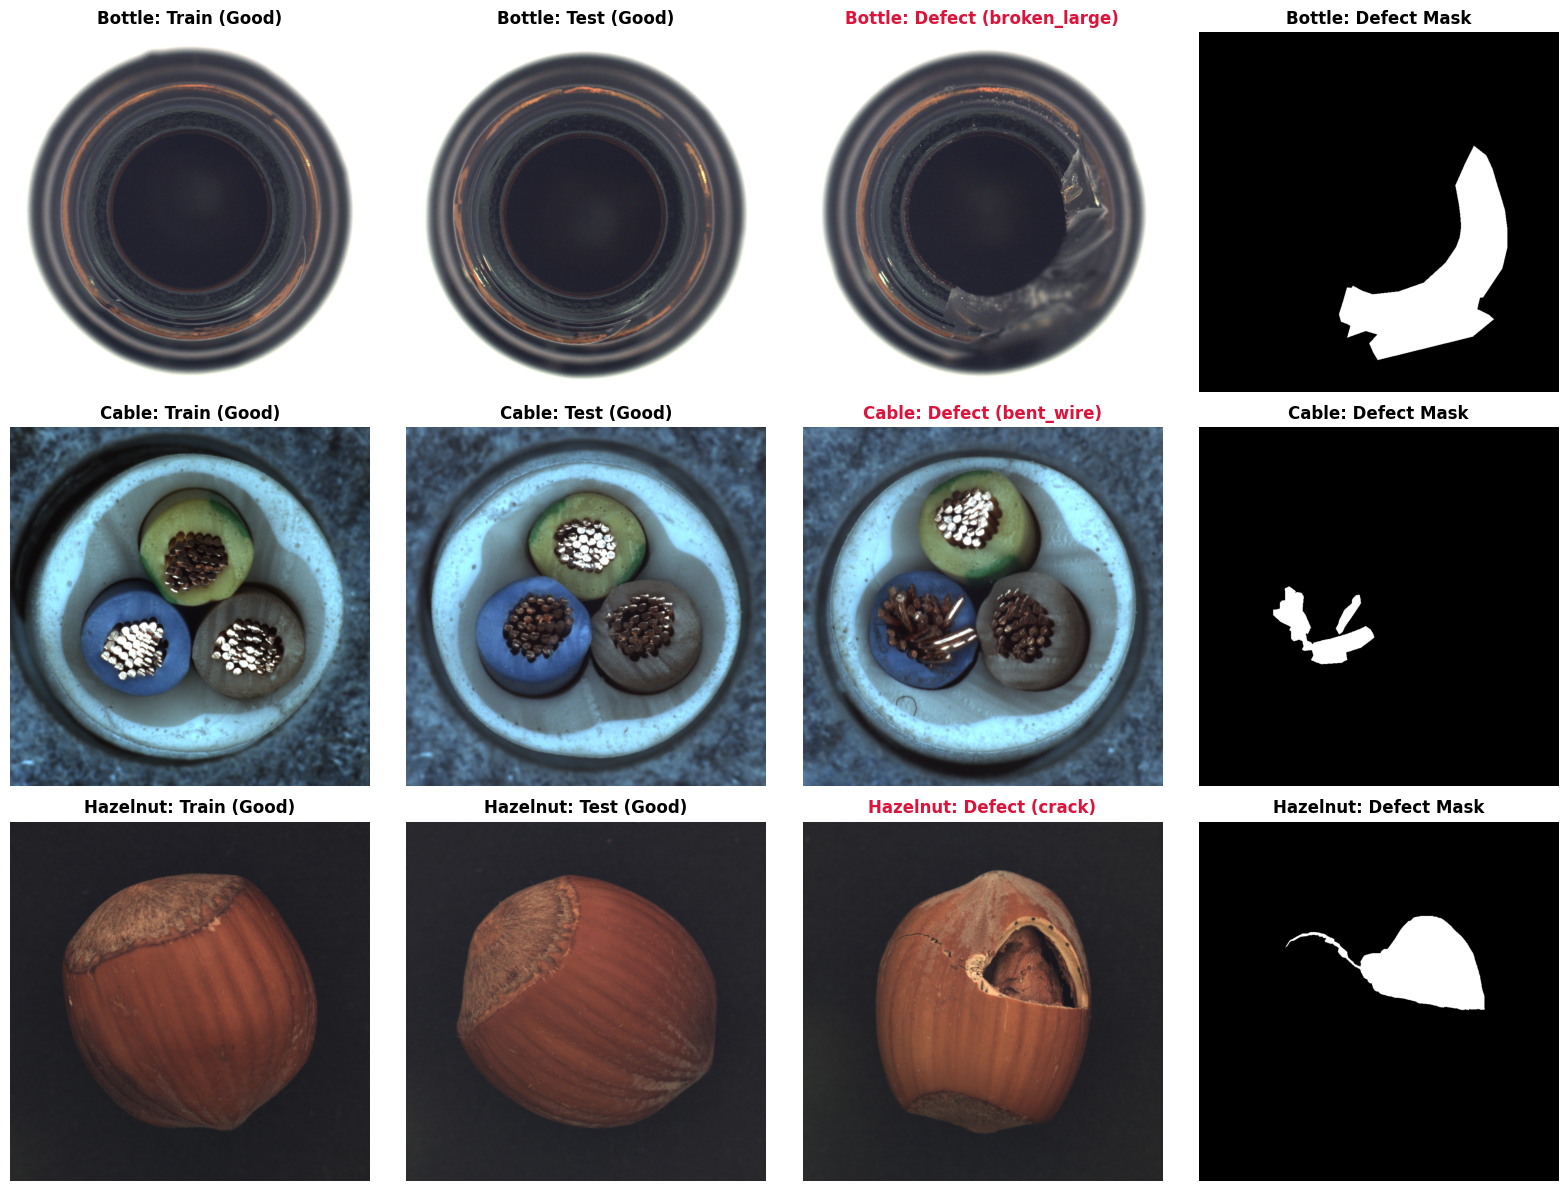

✅ Visualization complete and saved to: /content/results/plots/dataset_samples.png


In [5]:
# CELL 5: Visualize Samples: [Normal Train | Normal Test | Defect Test | Ground Truth Mask]
if len(metadata_df) == 0:
    print("⚠️ Cannot visualize: no images loaded in metadata_df.")
else:
    fig, axes = plt.subplots(len(CATEGORIES), 4, figsize=(16, 4 * len(CATEGORIES)))
    
    for r_idx, cat in enumerate(CATEGORIES):
        cat_df = metadata_df[metadata_df['category'] == cat]
        if len(cat_df) == 0:
            continue
        
        # 1. Normal Train
        train_goods = cat_df[(cat_df['split'] == 'train') & (cat_df['defect_type'] == 'good')]
        if len(train_goods) > 0:
            t_good = train_goods.iloc[0]
            axes[r_idx, 0].imshow(Image.open(t_good['image_path']))
            axes[r_idx, 0].set_title(f"{cat.title()}: Train (Good)", fontsize=12, fontweight='bold')
        axes[r_idx, 0].axis('off')
        
        # 2. Normal Test
        test_goods = cat_df[(cat_df['split'] == 'test') & (cat_df['defect_type'] == 'good')]
        if len(test_goods) > 0:
            test_good = test_goods.iloc[0]
            axes[r_idx, 1].imshow(Image.open(test_good['image_path']))
            axes[r_idx, 1].set_title(f"{cat.title()}: Test (Good)", fontsize=12, fontweight='bold')
        axes[r_idx, 1].axis('off')
        
        # 3. Defective Sample
        defect_rows = cat_df[(cat_df['split'] == 'test') & (cat_df['is_anomaly'] == 1)]
        if len(defect_rows) > 0:
            def_sample = defect_rows.iloc[0]
            axes[r_idx, 2].imshow(Image.open(def_sample['image_path']))
            axes[r_idx, 2].set_title(f"{cat.title()}: Defect ({def_sample['defect_type']})", fontsize=12, fontweight='bold', color='crimson')
            
            # 4. Ground Truth Mask
            if def_sample['mask_path']:
                mask = Image.open(def_sample['mask_path'])
                axes[r_idx, 3].imshow(mask, cmap='gray')
                axes[r_idx, 3].set_title(f"{cat.title()}: Defect Mask", fontsize=12, fontweight='bold')
            else:
                axes[r_idx, 3].imshow(np.zeros((224, 224)), cmap='gray')
                axes[r_idx, 3].set_title(f"{cat.title()}: No Mask", fontsize=12)
        axes[r_idx, 2].axis('off')
        axes[r_idx, 3].axis('off')
    
    plt.tight_layout()
    save_dir = PROJECT_ROOT / 'results' / 'plots'
    save_dir.mkdir(parents=True, exist_ok=True)
    plt.savefig(save_dir / 'dataset_samples.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(f"✅ Visualization complete and saved to: {save_dir / 'dataset_samples.png'}")